1. model_1: SquareGMM of Simon, feat=20, inflate_full=True, delta=0.01, max_feature_dim=20, max_model_dim=20, prior.gmm.max_num_cluster=20, EPOCHS=10, BATCH_SIZE=4, train.nlayer=4

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import pickle
import torch

In [2]:
model_1_dir = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/train_val_loss.pickle"
model_1_best_dir = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/best.ckpt"
model_1_best_val_dir = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/best_val.ckpt"
model_1_last_dir = "../ckpt/dataSGMM.context5000.feat20.R500.inf-fullTrue.LTFalse.gen1tr1True.reuse100.E10.step1000.bs4.lr0.001.emb256.hdim512.nhead4.nlayer4.ndevice1.numclusters20/seed0/last.ckpt"


Train loss: [0.34792209124565127, 0.32169654712080953, 0.29759065705537796, 0.21756765252351762, 0.17367724902927875, 0.1462290464863181, 0.128235241279006, 0.1191696281209588, 0.11181802693381905, 0.10539679509960115]
Val loss: [0.08715555092692376, 0.07169886665046216, 0.0644110307469964, 0.042163462337106467, 0.03823595622554422, 0.030661422527395187, 0.029426430485211312, 0.027412711715325715, 0.024914409256074577, 0.026650307562202217]
Train time 2470.707485437393


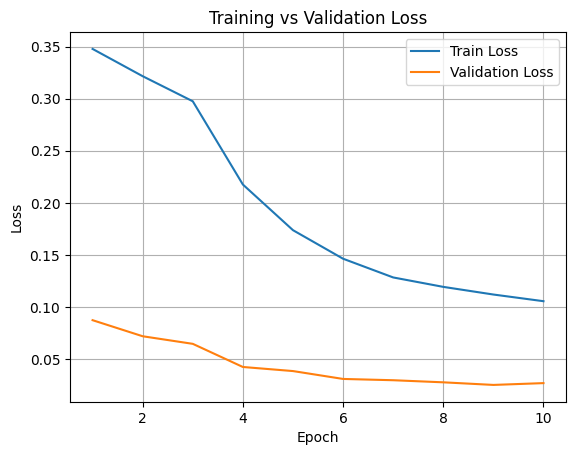

In [3]:
# load pickel
with open(model_1_dir, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]
train_time = data['train_time']

print("Train loss:", train_loss)
print("Val loss:", val_loss)
print("Train time", train_time)

# plot
epochs = range(1, len(train_loss) + 1)
plt.figure()
plt.plot(epochs, train_loss, label="Train Loss")
plt.plot(epochs, val_loss, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

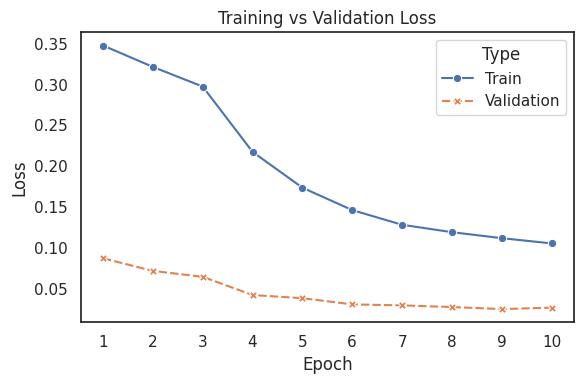

In [4]:
# load data
with open(model_1_dir, "rb") as f:
    data = pickle.load(f)

train_loss = data["train_loss"]
val_loss = data["val_loss"]

epochs = list(range(1, len(train_loss)+1))

# convert to dataframe (seaborn prefers tidy format)
df = pd.DataFrame({
    "Epoch": epochs + epochs,
    "Loss": train_loss + val_loss,
    "Type": ["Train"]*len(train_loss) + ["Validation"]*len(val_loss)
})

# seaborn style
sns.set_theme(style="white")  # darkgrid

plt.figure(figsize=(6,4))

ax = sns.lineplot(
    data=df,
    x="Epoch",
    y="Loss",
    hue="Type",
    style="Type",
    markers=True,
    dashes=True
)

# Force integer ticks
ax.xaxis.set_major_locator(MaxNLocator(len(epochs), integer=True))

plt.title("Training vs Validation Loss")
plt.tight_layout()

plt.show()

In [8]:
# load best.ckpt
ckpt_best = torch.load(model_1_best_dir, map_location="cpu")

print(ckpt_best.keys())
print(ckpt_best["epoch"])
print(ckpt_best["lr_schedulers"][0]['_last_lr'])
print(ckpt_best["train_losses"])
print(ckpt_best["val_losses"])

dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'train_losses', 'val_losses'])
9
[0.0]
[0.34792209124565127, 0.32169654712080953, 0.29759065705537796, 0.21756765252351762, 0.17367724902927875, 0.1462290464863181, 0.128235241279006, 0.1191696281209588, 0.11181802693381905, 0.10539679509960115]
[0.08715555092692376, 0.07169886665046216, 0.0644110307469964, 0.042163462337106467, 0.03823595622554422, 0.030661422527395187, 0.029426430485211312, 0.027412711715325715, 0.024914409256074577, 0.026650307562202217]


In [40]:
print(ckpt_best["state_dict"])

OrderedDict([('criterion.weight', tensor([0.5000, 0.5000])), ('model.transformer_encoder.layers.0.router_att.router', tensor([[[-0.5899, -0.1901, -0.6861,  ..., -1.2611,  0.3689, -1.0704]],

        [[ 0.1517,  0.1346, -2.5369,  ..., -0.2819,  2.1718,  0.0437]],

        [[ 0.6725,  0.5142, -2.7484,  ...,  1.3958,  2.1507, -0.7127]],

        ...,

        [[ 0.3980, -0.8548,  0.5680,  ...,  0.5633,  0.6027,  0.0588]],

        [[ 0.3475,  0.0326,  0.5053,  ...,  0.3375,  0.2406,  0.1271]],

        [[ 0.1130, -0.4085,  0.5438,  ..., -1.1529,  0.6015,  2.6915]]])), ('model.transformer_encoder.layers.0.router_att.att_compressor.in_proj_weight', tensor([[ 0.0333,  0.0257,  0.0455,  ...,  0.0523,  0.0332,  0.0001],
        [ 0.0653,  0.0708,  0.0056,  ...,  0.0262,  0.0585,  0.0402],
        [-0.0755, -0.0026, -0.0289,  ..., -0.0570,  0.0036,  0.0351],
        ...,
        [-0.0261,  0.0016,  0.0413,  ...,  0.0621, -0.0729,  0.0109],
        [-0.0160,  0.0499,  0.0061,  ..., -0.0172, -0.0

In [35]:
# load best_val.ckpt
ckpt_best_val = torch.load(model_1_best_val_dir, map_location="cpu")

print(ckpt_best_val.keys())
print(ckpt_best_val["epoch"])
print(ckpt_best_val["lr_schedulers"])
print(ckpt_best_val["train_losses"])
print(ckpt_best_val["val_losses"])

dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'train_losses', 'val_losses'])
8
[{'base_lrs': [0.001], 'last_epoch': 9, '_step_count': 10, '_is_initial': False, '_get_lr_called_within_step': False, '_last_lr': [3.806023374435663e-05], 'lr_lambdas': [None]}]
[0.34792209124565127, 0.32169654712080953, 0.29759065705537796, 0.21756765252351762, 0.17367724902927875, 0.1462290464863181, 0.128235241279006, 0.1191696281209588, 0.11181802693381905]
[0.08715555092692376, 0.07169886665046216, 0.0644110307469964, 0.042163462337106467, 0.03823595622554422, 0.030661422527395187, 0.029426430485211312, 0.027412711715325715, 0.024914409256074577]


In [4]:
# load last.ckpt
ckpt_last = torch.load(model_1_last_dir, map_location="cpu")

print(ckpt_last.keys())
print(ckpt_last["epoch"])
print(ckpt_last["lr_schedulers"])
print(ckpt_last["train_losses"])
print(ckpt_last["val_losses"])

dict_keys(['epoch', 'global_step', 'pytorch-lightning_version', 'state_dict', 'loops', 'callbacks', 'optimizer_states', 'lr_schedulers', 'train_losses', 'val_losses'])
9
[{'base_lrs': [0.001], 'last_epoch': 10, '_step_count': 11, '_is_initial': False, '_get_lr_called_within_step': False, '_last_lr': [0.0], 'lr_lambdas': [None]}]
[0.34792209124565127, 0.32169654712080953, 0.29759065705537796, 0.21756765252351762, 0.17367724902927875, 0.1462290464863181, 0.128235241279006, 0.1191696281209588, 0.11181802693381905, 0.10539679509960115]
[0.08715555092692376, 0.07169886665046216, 0.0644110307469964, 0.042163462337106467, 0.03823595622554422, 0.030661422527395187, 0.029426430485211312, 0.027412711715325715, 0.024914409256074577, 0.026650307562202217]


In [5]:
print(ckpt_last["state_dict"])

OrderedDict([('criterion.weight', tensor([0.5000, 0.5000])), ('model.transformer_encoder.layers.0.router_att.router', tensor([[[-0.5899, -0.1901, -0.6861,  ..., -1.2611,  0.3689, -1.0704]],

        [[ 0.1517,  0.1346, -2.5369,  ..., -0.2819,  2.1718,  0.0437]],

        [[ 0.6725,  0.5142, -2.7484,  ...,  1.3958,  2.1507, -0.7127]],

        ...,

        [[ 0.3980, -0.8548,  0.5680,  ...,  0.5633,  0.6027,  0.0588]],

        [[ 0.3475,  0.0326,  0.5053,  ...,  0.3375,  0.2406,  0.1271]],

        [[ 0.1130, -0.4085,  0.5438,  ..., -1.1529,  0.6015,  2.6915]]])), ('model.transformer_encoder.layers.0.router_att.att_compressor.in_proj_weight', tensor([[ 0.0333,  0.0257,  0.0455,  ...,  0.0523,  0.0332,  0.0001],
        [ 0.0653,  0.0708,  0.0056,  ...,  0.0262,  0.0585,  0.0402],
        [-0.0755, -0.0026, -0.0289,  ..., -0.0570,  0.0036,  0.0351],
        ...,
        [-0.0261,  0.0016,  0.0413,  ...,  0.0621, -0.0729,  0.0109],
        [-0.0160,  0.0499,  0.0061,  ..., -0.0172, -0.0